In [4]:
from plotnine import *
from scipy.io import loadmat
from pathlib import Path
import pandas as pd
import numpy as np

Experiments to get done
- 5kms ISO+NAADP but OCaR WT
- 1 uM ISO 10kms 5Hz Train
- Train with ISO NAADP and OCaR KO for longer

Experiments needed list
- Basal
    - 100s SS
    - Spike
    - Two spikes (refractory)
    - Train (10s, 5Hz)
- 1 uM ISO
    - 600s SS
    - Spike
    - Train (10s, 5Hz)
- 1 uM ISO + 30 nM NAADP, OCaR KO (0.95)
    - Spike after initial Ca release from Lys
    - Train (5Hz)
- 1 uM ISO + 30 nM NAADP, OCaR WT (0.05)
    - Train (5Hz)
- No ISO + 30 nM NAADP, OCaR KO (0.95)
    - Train (5Hz)

In [2]:
parent_path = Path.cwd().parent
data_path = Path(parent_path / "+experiments")

In [162]:
data = loadmat(Path(data_path / "longISO_spike_6kms_1_03_KO95.mat"), squeeze_me=True, struct_as_record=False)
struct = data["S"]
print(struct._fieldnames)
result = {name: getattr(struct, name) for name in struct._fieldnames}

['J', 'I', 'X', 'T']


In [171]:
#For one line
df = pd.DataFrame({
    't': result["T"],
    'x': result["X"][:,154]#+result["X"][:,104]#+result["X"][:,116]+result["X"][:,117]
})

In [172]:
df = df.iloc[25000:35000].copy()
#df["t"] = np.arange(len(df)) * 0.1

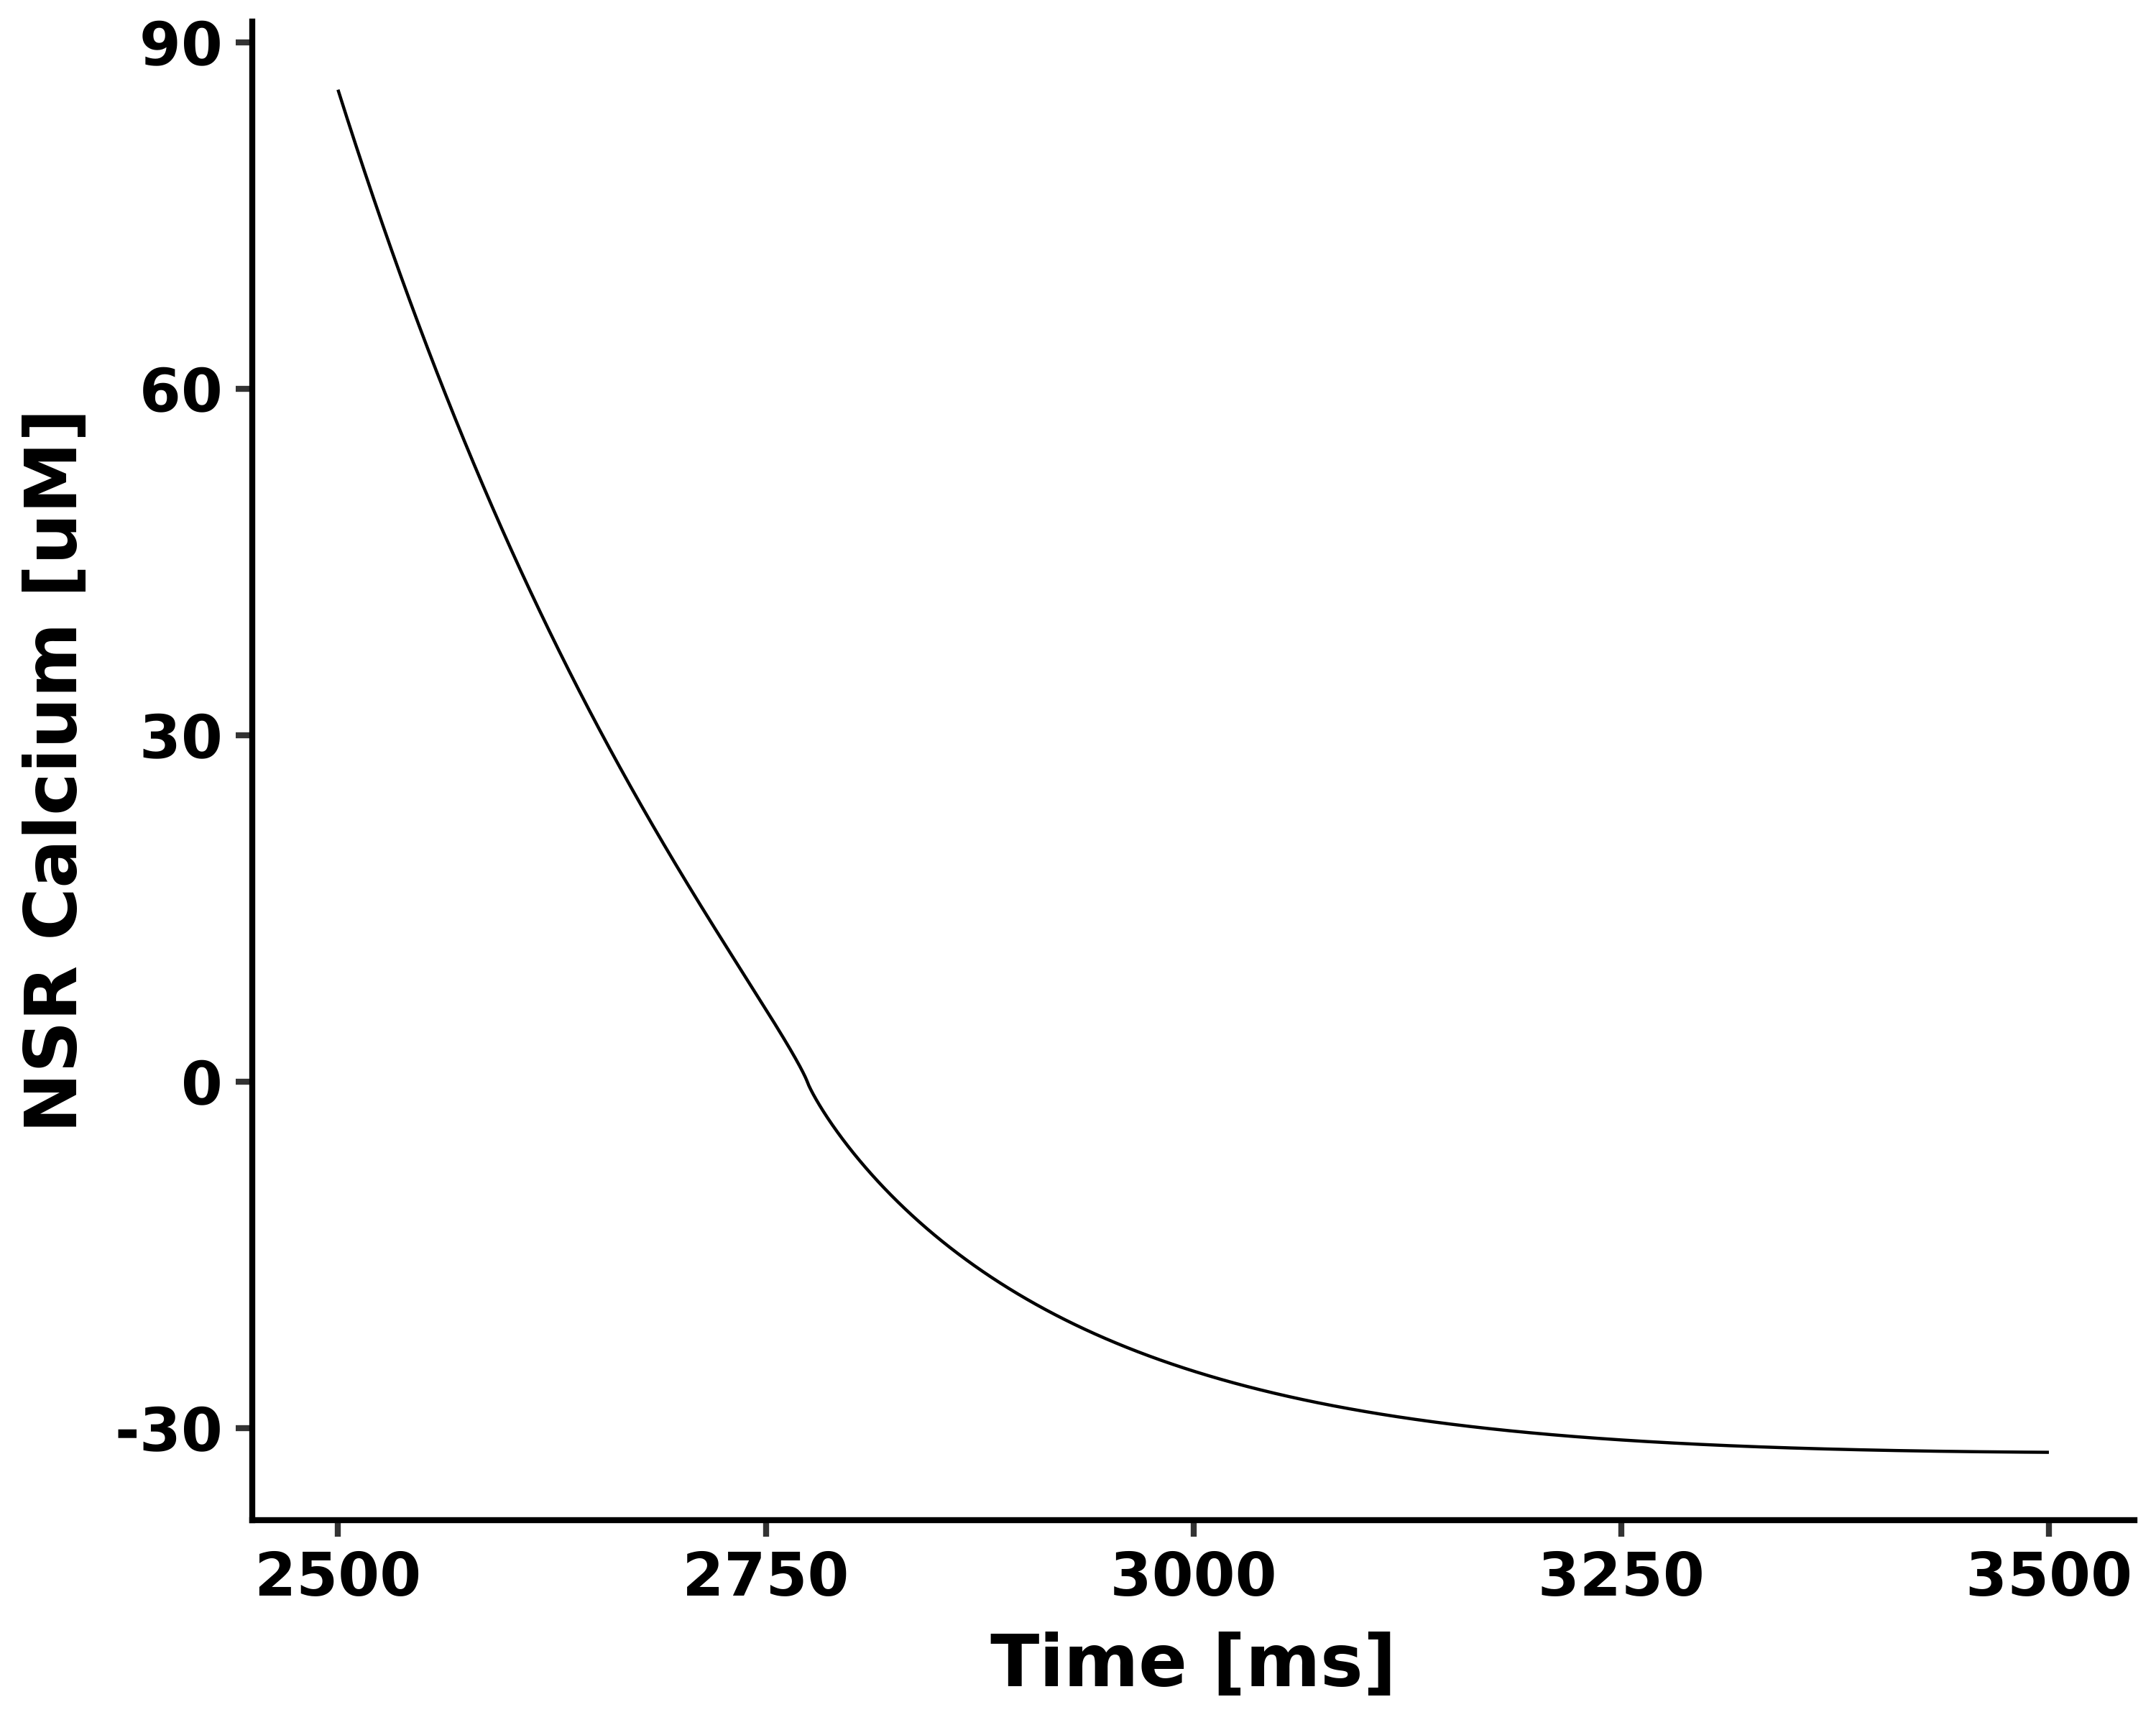

In [173]:
plot = (
    ggplot(df, aes(x='t', y='x'))
    + geom_line(color='black', size=0.3)
    + labs(x='Time [ms]', y='NSR Calcium [uM]', title='')
    + theme_bw()
    + theme(
        panel_grid_major=element_blank(),
        panel_grid_minor=element_blank(),
        panel_border=element_blank(), #element_rect(color='black', size=0.8),
        axis_line=element_line(color='black'),
        axis_text=element_text(color='black', weight="bold", size=10),
        axis_title=element_text(color='black', weight="bold", size=12),
        figure_size=(5, 4),
        dpi=300
    )
   # + geom_vline(
   #     xintercept=[4100, 4300, 4500, 4700, 4900, 5100, 5300, 5500, 5700, 5900],
   #     colour="black",  # add colour
   #     size=0.3,  # set line thickness
   #     linetype="dotted",  # set line type
   # )
)

plot

# For multiple lines per plot

In [2]:
from pathlib import Path
import pandas as pd
from scipy.io import loadmat
from plotnine import *

In [160]:
parent_path = Path.cwd().parent
data_path = Path(parent_path / "+experiments")

# --- Time window to plot (same units as result["T"], i.e. ms) -------------
t_min = 0      # None = from the start
t_max = 2000      # None = until the end
rebase_time = True   # True: shift so the window starts at 0

def load_result(filename):
    data = loadmat(data_path / filename, squeeze_me=True, struct_as_record=False)
    struct = data["S"]
    return {name: getattr(struct, name) for name in struct._fieldnames}

# (filename, legend label, column of X)
series_defs = [
    ("longISO_spike_6kms_1_03_KO95.mat",                "CAX",        13),
    ("longISO_spike_6kms_1_03_KO95.mat",               "TPC",      14),
    ("longISO_spike_6kms_1_03_KO95.mat",                    "V-ATPase",           15 )
]

# --- Build one long-format DataFrame, subset per series --------------------
frames = []
for filename, label, col in series_defs:
    result = load_result(filename)
    t = np.asarray(result["T"])
    x = np.asarray(result["J"])[:, col]

    mask = np.ones_like(t, dtype=bool)
    if t_min is not None:
        mask &= t >= t_min
    if t_max is not None:
        mask &= t <= t_max

    t_sel, x_sel = t[mask], x[mask]
    if rebase_time and len(t_sel) > 0:
        t_sel = t_sel - t_sel[0]

    frames.append(pd.DataFrame({'t': t_sel, 'x': x_sel, 'series': label}))

df = pd.concat(frames, ignore_index=True)
labels = [label for _, label, _ in series_defs]
df['series'] = pd.Categorical(df['series'], categories=labels, ordered=True) 

In [161]:
# --- Line styles: first solid, then different dash patterns ---
linetypes = ['solid', 'dashed', 'dotted', 'dashdot', (0, (5, 1, 1, 1)), (0, (1, 3))]
linetype_map = {lab: linetypes[k % len(linetypes)] for k, lab in enumerate(labels)}

# --- Colors (colorblind-friendly Okabe-Ito palette) -----------------------
colors = ['#000000', '#D55E00', '#0072B2', '#009E73', '#CC79A7', '#E69F00']
color_map = {lab: colors[k % len(colors)] for k, lab in enumerate(labels)}

# --- Plot ---
plot = (
    ggplot(df, aes(x='t', y='x', linetype='series'))
    + geom_line(color='black', size=0.7)
    #+ scale_linetype_manual(values=linetype_map) #+ scale_color_manual(values=color_map)
    + scale_color_manual(values=color_map)
    + labs(x='Time [ms]', y='Membrane Potential [mV]', title='5 Hz Action Potential', linetype='')
    + theme_bw()
    + theme(
        panel_grid_major=element_blank(),
        panel_grid_minor=element_blank(),
        panel_border=element_blank(),
        axis_line=element_line(color='black'),
        axis_text=element_text(color='black', weight='bold', size=10),
        axis_title=element_text(color='black', weight='bold', size=12),
        legend_text=element_text(color='black', size=10),
        legend_key=element_blank(),
        legend_key_width=30,
        legend_position='right',
        figure_size=(6, 4),
        dpi=300
    )
)

plot

/home/saez/miniconda3/envs/cardio_plot/lib/python3.14/site-packages/plotnine/scales/scale_linetype.py:45: PlotnineWarning: Using linetype for an ordinal variable is not advised.


ValueError: Cannot get a null value for type: <class 'numpy.complex128'>

In [ ]:
plot.save('plot.png', dpi=300)